# 05 — CSP: formulação, inferência e heurísticas

Experiências detalhadas do CSP (`src/csp.py`). A formulação completa está no notebook principal,
secção 6. Em resumo:

* **variáveis:** uma por pedido;
* **domínio:** (veículo, dia, posição de viagem), segundo um modelo fixo de posições por dia;
* **restrições:**
  * unárias: tipo e dia;
  * binárias: capacidade e compatibilidade temporal na mesma viagem, precedência e sequência no mesmo
    veículo;
  * globais: capacidade de cada viagem e um horário completo viável;
* **restrição suave:** minimizar os km, tratada pela ordenação de valores e pelo branch & bound.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, evaluate, schedule_table, State, PICKUP, DELIVERY
from src.model import check_solution
from src.model import plot_routes, plot_gantt, plot_histories

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
RUN_HEAVY = False   # True: volta a correr as pesquisas longas em vez de ler reports/
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}

from src.csp import RoutingCSP, solve, TEMPLATE

## 1. Variáveis, domínios e restrições

In [2]:
for ds, p in PROBLEMS.items():
    c = RoutingCSP(p)
    n_bin = sum(map(len, c.neigh.values())) // 2
    incompat = sum(1 for (a, b), ok in c.compat.items() if a < b and not ok and c._same_group(a, b))
    print(f"{ds}: {len(c.vars)} variáveis, {sum(map(len, c.domains.values()))} valores, "
          f"{n_bin} pares com restrição binária, {incompat} pares incompatíveis na mesma viagem")
c = RoutingCSP(tiny)
pd.DataFrame({r: dict(tipo=tiny.requests[r].kind, dia=c.day[r], dominio=len(d), vizinhos=len(c.neigh[r]))
              for r, d in c.domains.items()}).T

tiny: 18 variáveis, 144 valores, 149 pares com restrição binária, 8 pares incompatíveis na mesma viagem
small: 37 variáveis, 298 valores, 653 pares com restrição binária, 63 pares incompatíveis na mesma viagem


,tipo,dia,dominio,vizinhos
P1,P,0,4,17
P2,P,1,4,16
P3,P,0,4,17
P4,P,1,4,16
P5,P,0,4,17
P6,P,1,4,15
D1,D,1,10,17
D2,D,1,10,15
D3,D,1,10,17
D4,D,0,10,17


In [3]:
# AC-3 na raiz: quantos valores remove antes de começar
for ds, p in PROBLEMS.items():
    c = RoutingCSP(p)
    dom = {r: list(d) for r, d in c.domains.items()}
    before = sum(map(len, dom.values()))
    removed = c.ac3(dom, {})
    print(ds, "valores antes:", before, "| removidos pelo AC-3:", removed)

tiny valores antes: 144 | removidos pelo AC-3: 0
small valores antes: 298 | removidos pelo AC-3: 0


## 2. Comparação de configurações

São comparadas todas as combinações de:

* inferência: nenhuma, forward checking ou MAC (FC + AC-3);
* ordem das variáveis: estática ou MRV;
* ordem dos valores: estática ou *soft*;
* FC global: sim ou não.

Os resultados vêm de `reports/csp.csv`, com um orçamento de 20 000 atribuições por corrida.

In [4]:
res = pd.read_csv(REPORTS / "csp.csv")
nopt = res[~res.optimize]
nopt.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"], values="backtracks", aggfunc="first")

dataset                          small        tiny      
global_fc                        False True  False True 
inference var_order value_order                         
fc        mrv       soft             1     1     3     0
                    static           5     0     3     0
          static    soft            21     5     7     0
                    static           4     0     3     0
mac       mrv       soft             0     0     3     0
                    static           5     0     3     0
          static    soft            20     4     7     0
                    static           4     0     3     0
none      mrv       soft            20     1     7     0
                    static           4     0     3     0
          static    soft         19976     5     7     0
                    static           4     0     3     0

In [5]:
nopt.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"], values="cost_km", aggfunc="first")

dataset                           small            tiny        
global_fc                         False   True    False   True 
inference var_order value_order                                
fc        mrv       soft         825.85  860.72  659.27  662.47
                    static       872.98  901.58  659.27  700.17
          static    soft         931.69  966.56  659.27  680.50
                    static       846.54  875.14  659.27  680.50
mac       mrv       soft         825.85  860.72  659.27  662.47
                    static       872.98  901.58  659.27  700.17
          static    soft         931.69  966.56  659.27  680.50
                    static       846.54  875.14  659.27  680.50
none      mrv       soft         931.69  860.72  659.27  662.47
                    static       846.54  901.58  659.27  700.17
          static    soft            NaN  966.56  659.27  680.50
                    static       846.54  875.14  659.27  680.50

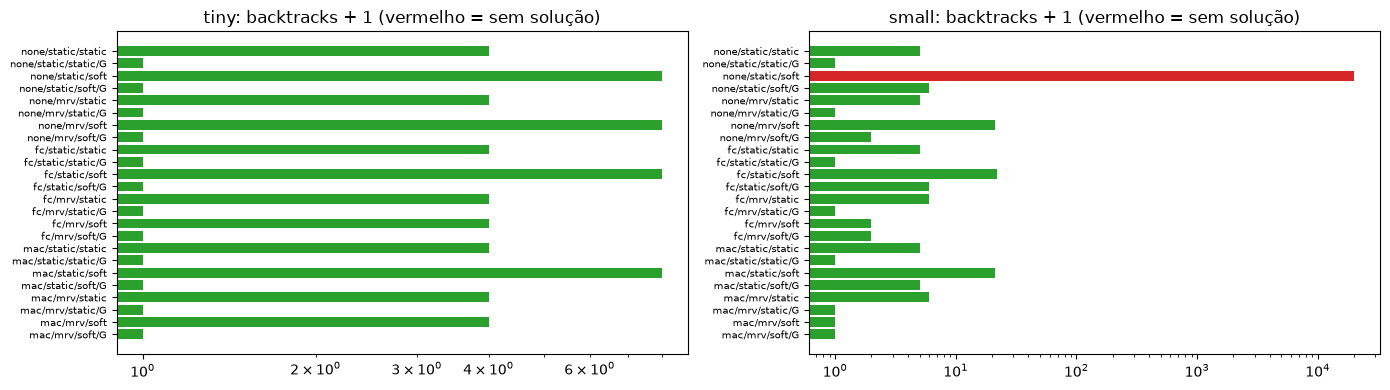

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, ds in zip(ax, ("tiny", "small")):
    d = nopt[nopt.dataset == ds].copy()
    d["cfg"] = d.inference + "/" + d.var_order + "/" + d.value_order + d.global_fc.map({True: "/G", False: ""})
    a_.barh(d.cfg, d.backtracks + 1, color=["tab:green" if pd.notna(k) else "tab:red" for k in d.cost_km])
    a_.set_xscale("log"); a_.invert_yaxis(); a_.set_title(f"{ds}: backtracks + 1 (vermelho = sem solução)")
    a_.tick_params(axis="y", labelsize=7)
fig.tight_layout()

## 3. Execução aqui no small (melhor configuração)

{'inference': 'mac', 'var_order': 'mrv', 'value_order': 'soft', 'global_fc': True, 'optimize': False, 'status': 'feasible', 'cost_km': 860.72, 'assignments': 37, 'backtracks': 0, 'checks': 5004, 'pruned': 135, 'solutions': 1, 'seconds': 0.245}
{'km': 860.72, 'feasible': True, 'trips': 8, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2534.5, 'route_min': 1581.9} | verificador por linha: True


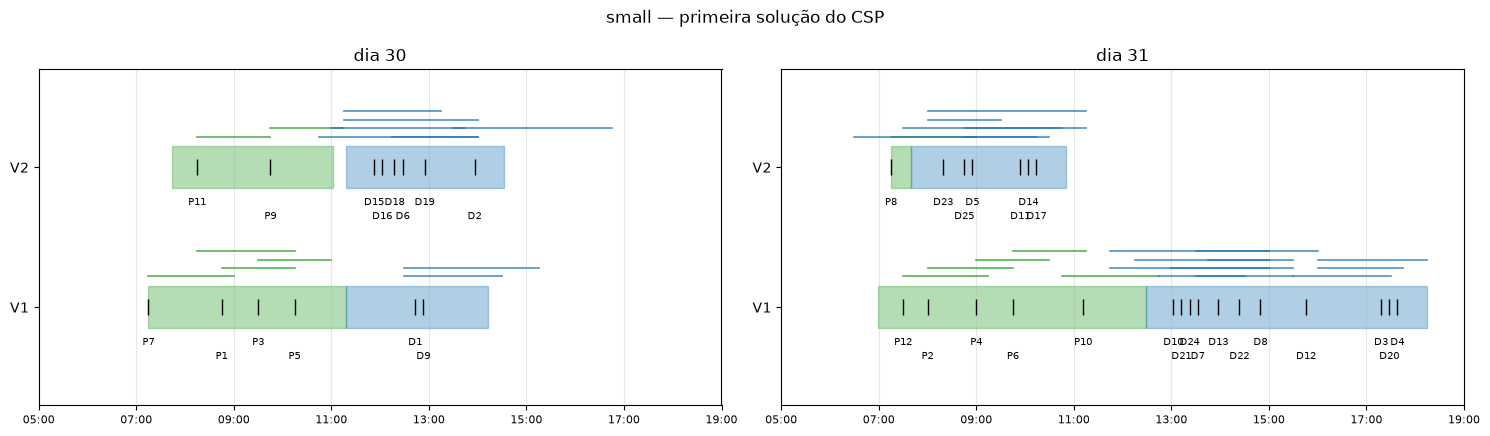

In [7]:
r = solve(small, inference="mac", var_order="mrv", value_order="soft", global_fc=True)
print(r.summary())
ev = evaluate(small, r.solution)
print(ev.summary(), "| verificador por linha:", check_solution(small, ev).valid)
plot_gantt(small, ev, "small — primeira solução do CSP");

## 4. Sensibilidade ao modelo de posições

O modelo de posições fixa o número máximo de viagens de cada tipo por dia e por veículo. Com poucas
posições, o problema pode ficar sem solução. Com muitas, o domínio cresce e surgem simetrias, porque
uma posição vazia antes ou depois de outra dá a mesma solução. A tabela mostra o efeito com FC global.

In [8]:
rows = []
for tpl in ("DPD", "DPDPD", "DPDDPDD", "DDPDDPDDD"):
    for ds, p in PROBLEMS.items():
        r = solve(p, global_fc=True, template=tuple(tpl), max_assignments=5_000, time_limit=30)
        rows.append(dict(modelo=tpl, dataset=ds, estado=r.status, km=r.cost, atribuicoes=r.assignments,
                         backtracks=r.backtracks, segundos=round(r.seconds, 2)))
pd.DataFrame(rows).pivot(index="modelo", columns="dataset", values=["estado", "km", "backtracks"])

estado                km         backtracks     
dataset       small      tiny   small    tiny      small tiny
modelo                                                       
DDPDDPDDD  feasible  feasible  860.72  662.47          0    0
DPD        feasible  feasible  860.72   642.8          0    0
DPDDPDD    feasible  feasible  860.72  662.47          0    0
DPDPD      feasible  feasible  860.72  662.47          0    0

## 5. Restrição suave: branch & bound

Depois da primeira solução, a pesquisa continua com o limite km(parcial) < melhor km. O gráfico mostra
como o melhor custo desce com o número de atribuições.

tiny {'inference': 'mac', 'var_order': 'mrv', 'value_order': 'soft', 'global_fc': True, 'optimize': True, 'status': 'best found (limit)', 'cost_km': 641.24, 'assignments': 3000, 'backtracks': 2987, 'checks': 65783, 'pruned': 1646, 'solutions': 3, 'seconds': 3.169}


small {'inference': 'mac', 'var_order': 'mrv', 'value_order': 'soft', 'global_fc': True, 'optimize': True, 'status': 'best found (limit)', 'cost_km': 840.04, 'assignments': 3000, 'backtracks': 2971, 'checks': 60268, 'pruned': 5344, 'solutions': 3, 'seconds': 4.572}


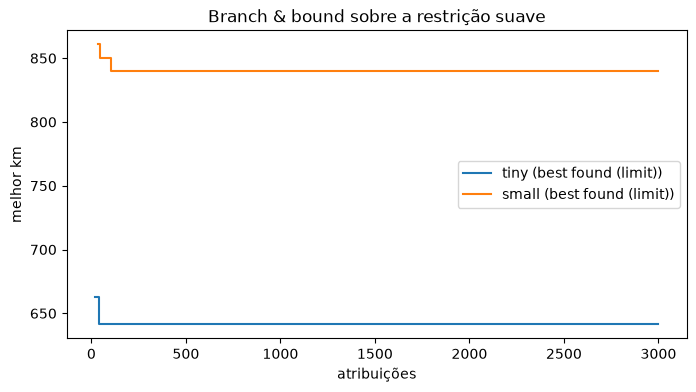

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for ds, p in PROBLEMS.items():
    r = solve(p, global_fc=True, optimize=True, max_assignments=3_000, time_limit=60)
    xs = [a for a, _, _ in r.improvements]; ys = [k for _, _, k in r.improvements]
    ax.step(xs + [r.assignments], ys + [ys[-1]], where="post", label=f"{ds} ({r.status})")
    print(ds, r.summary())
ax.set_xlabel("atribuições"); ax.set_ylabel("melhor km"); ax.legend(); ax.set_title("Branch & bound sobre a restrição suave");

## 6. Conclusões

* **No tiny**, o problema é pequeno e todas as configurações encontram uma solução com poucos
  backtracks (no máximo 7).
* **No small** vê-se o valor da inferência. A restrição binária de **sequência** deixa o forward
  checking retirar dos pedidos por atribuir as viagens que já não cabem no horário. Com ordem
  *soft*, o backtracking sem inferência cai em *thrashing* com a ordem estática das variáveis (sem
  solução após 20 000 atribuições) e precisa de 20 backtracks com MRV. Com MRV, FC e MAC resolvem com
  1 e 0 backtracks (ver a tabela da secção 2).
* **O AC-3 na raiz** não remove nada: há sempre um valor de suporte noutro veículo ou noutra viagem. É
  durante a pesquisa (MAC) que ajuda.
* **O FC global** (filtrar valores com o simulador) resolve o small praticamente sem backtracking, em
  todas as configurações. Cada nó fica mais caro, mas a árvore fica minúscula (no máximo 5 backtracks). Em troca, as primeiras
  soluções têm mais km.
* **A ordenação *soft*** dá primeiras soluções com menos km. O **branch & bound** continua a melhorá-las,
  mas o espaço é grande e o orçamento esgota-se antes de provar o ótimo.
* **O modelo de posições** é uma escolha de modelação. Tem de permitir viagens suficientes por dia;
  posições a mais só aumentam o domínio e as simetrias.